# Company A: Handset-Age Churn Retention (PoC)
**GCI World 2026 Winter, Final Assignment** | Author: *<your Omnicampus account name>*

**Business question (one sentence):** *Which Company A customers are about to leave, and can we keep them by offering a handset upgrade before their phone gets "old"?*

**ML task:** binary classification of `churn` (left 31-60 days after the observation date).
**Plan:** EDA -> feature engineering -> compare 5 models -> pick best -> turn the scores into a retention-campaign business case.

## 0. Setup

In [1]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, confusion_matrix
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

SEED = 42
STAY, CHURN, GREY = "#3B6FB6", "#E07B39", "#8A8F98"   # blue / orange: colour-blind safe pair
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11, "axes.titleweight": "bold",
                     "axes.titlesize": 13})
Path("figures").mkdir(exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()

# --- Google Colab users: uncomment the next 3 lines and change the folder name ---
# from google.colab import drive; drive.mount('/content/drive')
# os.chdir("/content/drive/MyDrive/Final Assignment")

## 1. Market context (summary; sources are listed on the slides and in the reference list)
- Acquiring a mobile customer costs about **4x the average monthly ARPU** (STL Partners); retention is cheaper than acquisition (McIlroy & Barnett 2000, as cited in arXiv:1607.07792).
- Typical monthly churn: **0.75-3% postpay, 3-5% prepay** (STL Partners). Operators lose **20-40% of customers per year** (arXiv 1607.07792).
- Local view (Pakistan): ~200.5 million mobile subscribers at end-2025 (PTA via Profit/Pakistan Today); Jazz still leads at ~36% share but lost share to Zong and Ufone in mid-2026 (PhoneWorld). A market where customers can switch easily makes retention a share-defence tool. (Company A's own records cover US-style regions such as Chicago and New York, so Pakistan is used here as a comparison market.)
- Handset subsidies / early-upgrade offers are a standard retention lever for customers about to churn (STL Partners).

## 2. Load and merge the data

In [2]:
base = Path.cwd() / "data" / "telecom"
client = pd.read_csv(base / "Client.csv")
record = pd.read_csv(base / "Record.csv")
df = record.merge(client, on="Customer_ID", how="inner", validate="1:1")
print("Client", client.shape, "| Record", record.shape, "| Merged", df.shape)
print("Customer_ID unique:", df.Customer_ID.is_unique)

Client (100000, 50) | Record (100000, 51) | Merged (100000, 100)
Customer_ID unique: True


## 3. EDA

### 3.1 Missing values and target balance

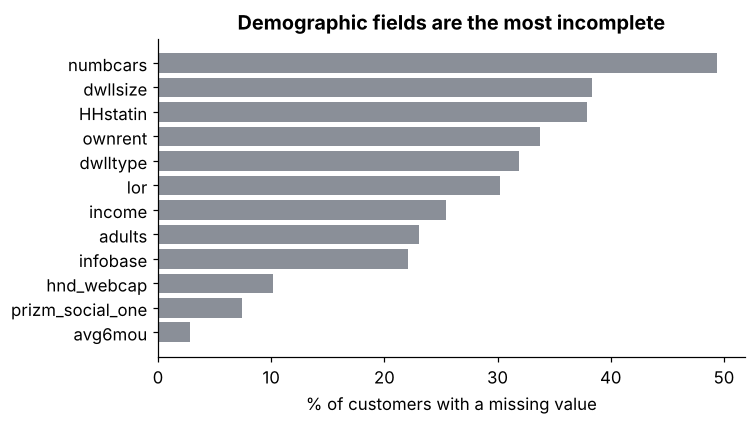

churn
0    0.504
1    0.496
Name: proportion, dtype: float64


In [3]:
miss = (df.isna().mean() * 100).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(miss.index[::-1], miss.values[::-1], color=GREY)
ax.set_xlabel("% of customers with a missing value"); ax.set_title("Demographic fields are the most incomplete")
save("01_missing")
print(df.churn.value_counts(normalize=True).round(3))

Churn is ~50/50 (unusual; real telecom churn is far lower). So **accuracy is a fair metric here** (random guessing = 0.50), and we also report **AUC**. We return to this caveat in the business case.

### 3.2 Key finding: handset age

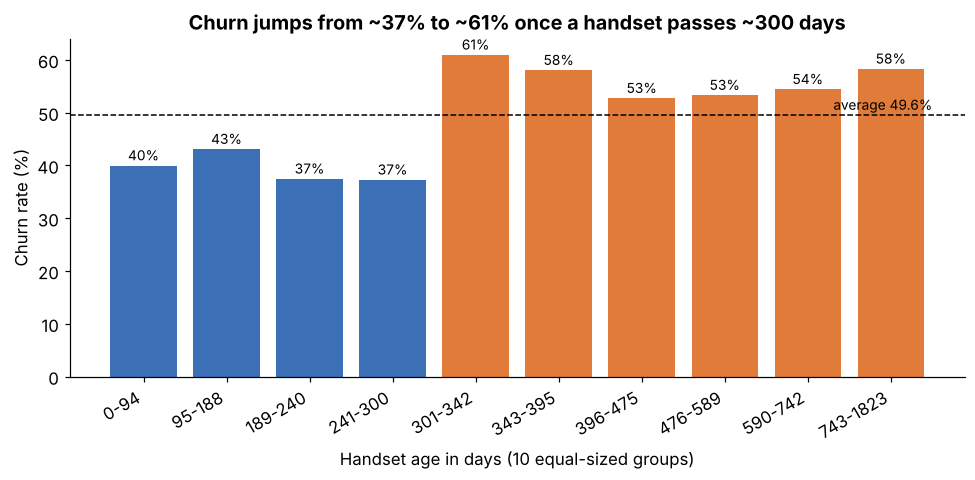

                 churn_rate     lo      hi
eq_decile                                 
(-5.001, 94.0]        0.400   -5.0    94.0
(94.0, 188.0]         0.431   95.0   188.0
(188.0, 240.0]        0.375  189.0   240.0
(240.0, 300.0]        0.373  241.0   300.0
(300.0, 342.0]        0.610  301.0   342.0
(342.0, 395.0]        0.581  343.0   395.0
(395.0, 475.0]        0.527  396.0   475.0
(475.0, 589.0]        0.533  476.0   589.0
(589.0, 742.0]        0.544  590.0   742.0
(742.0, 1823.0]       0.583  743.0  1823.0


In [4]:
df["eq_decile"] = pd.qcut(df.eqpdays, 10, duplicates="drop")
g = df.groupby("eq_decile", observed=True).agg(churn_rate=("churn", "mean"), lo=("eqpdays", "min"), hi=("eqpdays", "max"))
labels = [f"{max(int(a),0)}-{int(b)}" for a, b in zip(g.lo, g.hi)]
fig, ax = plt.subplots(figsize=(9, 4.5))
cols = [CHURN if r > 0.5 else STAY for r in g.churn_rate]
ax.bar(range(len(g)), g.churn_rate * 100, color=cols)
ax.axhline(df.churn.mean() * 100, color="black", lw=1, ls="--"); ax.text(len(g)-0.5, df.churn.mean()*100+1, "average 49.6%", ha="right", fontsize=9)
ax.set_xticks(range(len(g))); ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Handset age in days (10 equal-sized groups)")
ax.set_title("Churn jumps from ~37% to ~61% once a handset passes ~300 days")
for i, r in enumerate(g.churn_rate): ax.text(i, r*100+1, f"{r*100:.0f}%", ha="center", fontsize=9)
save("02_eqpdays_decile")
print(g.assign(churn_rate=g.churn_rate.round(3)))

In [5]:
old = df.eqpdays >= 300
print(f"Handset < 300 days : n={(~old).sum():,}  churn={df[~old].churn.mean():.1%}")
print(f"Handset >= 300 days: n={old.sum():,}  churn={df[old].churn.mean():.1%}")
print("Median handset age  stayed vs churned:", df[df.churn==0].eqpdays.median(), df[df.churn==1].eqpdays.median())

Handset < 300 days : n=39,927  churn=39.4%
Handset >= 300 days: n=60,073  churn=56.3%
Median handset age  stayed vs churned: 310.0 366.0


### 3.3 Tenure, handset type and plan features

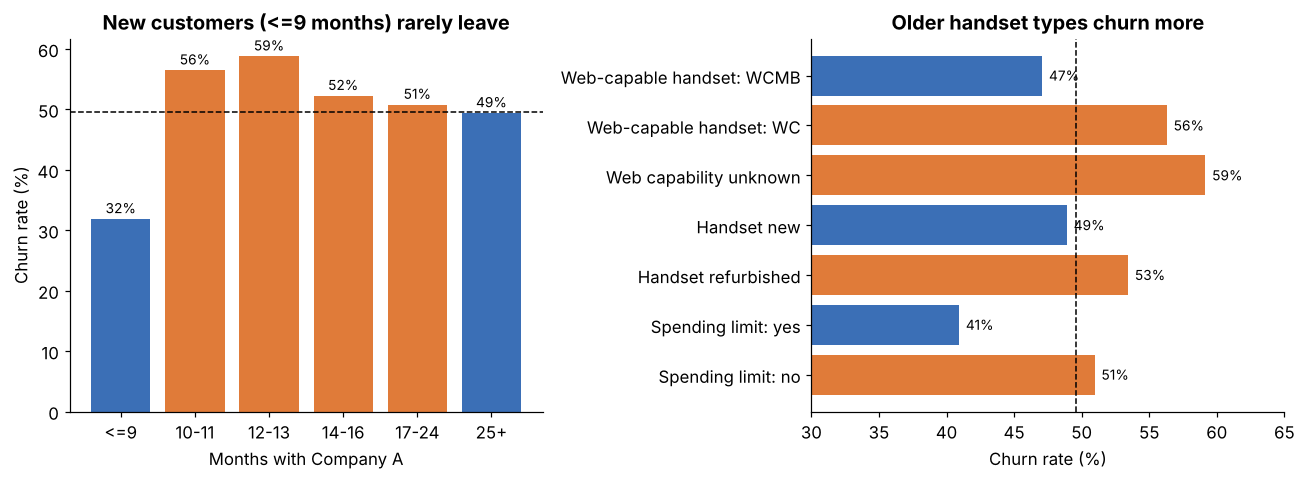

In [6]:
df["tenure_bin"] = pd.cut(df.months, [0, 9, 11, 13, 16, 24, 70], labels=["<=9", "10-11", "12-13", "14-16", "17-24", "25+"])
t = df.groupby("tenure_bin", observed=True).churn.mean() * 100

seg = {}
seg["Web-capable handset: WCMB"] = df[df.hnd_webcap == "WCMB"].churn.mean()
seg["Web-capable handset: WC"] = df[df.hnd_webcap == "WC"].churn.mean()
seg["Web capability unknown"] = df[df.hnd_webcap.isna()].churn.mean()
seg["Handset new"] = df[df.refurb_new == "N"].churn.mean()
seg["Handset refurbished"] = df[df.refurb_new == "R"].churn.mean()
seg["Spending limit: yes"] = df[df.asl_flag == "Y"].churn.mean()
seg["Spending limit: no"] = df[df.asl_flag == "N"].churn.mean()
s = pd.Series(seg) * 100

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].bar(t.index.astype(str), t.values, color=[STAY if v < 50 else CHURN for v in t.values])
axs[0].axhline(49.6, color="black", ls="--", lw=1)
axs[0].set_title("New customers (<=9 months) rarely leave"); axs[0].set_xlabel("Months with Company A"); axs[0].set_ylabel("Churn rate (%)")
for i, v in enumerate(t.values): axs[0].text(i, v+1, f"{v:.0f}%", ha="center", fontsize=9)
axs[1].barh(s.index[::-1], s.values[::-1], color=[STAY if v < 50 else CHURN for v in s.values[::-1]])
axs[1].axvline(49.6, color="black", ls="--", lw=1); axs[1].set_xlim(30, 65)
axs[1].set_title("Older handset types churn more"); axs[1].set_xlabel("Churn rate (%)")
for i, v in enumerate(s.values[::-1]): axs[1].text(v+0.5, i, f"{v:.0f}%", va="center", fontsize=9)
save("03_tenure_segments")

### 3.4 Usage and revenue behaviour; are columns leaking the target?

               stayed  churned
rev_Mean        48.88    47.49
mou_Mean       380.50   329.75
change_mou      -3.00   -10.00
custcare_Mean    0.00     0.00
drop_blk_Mean    5.67     5.33
hnd_price      129.99    99.99
months          16.00    17.00
eqpdays        310.00   366.00


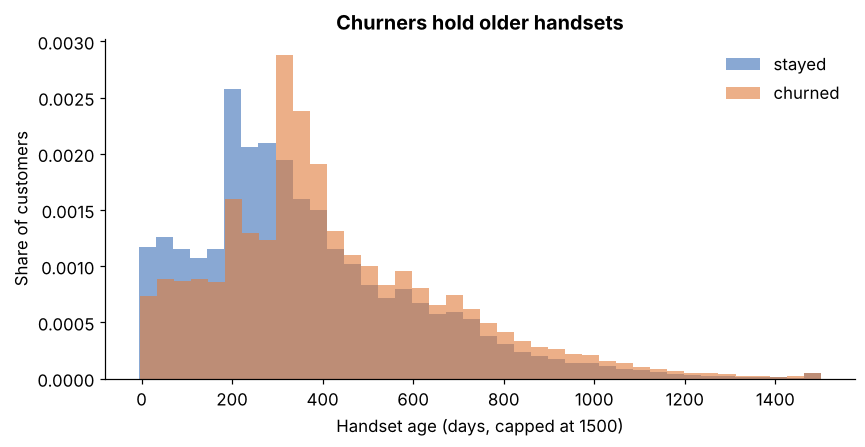


Highest |correlation| with churn (a value near 1 would signal leakage):
eqpdays          0.113
hnd_price        0.103
totmrc_Mean      0.069
mou_Mean         0.057
mou_cvce_Mean    0.052
complete_Mean    0.052
comp_vce_Mean    0.052
avg3mou          0.050
Name: churn, dtype: float64


In [7]:
cmp = df.groupby("churn")[["rev_Mean", "mou_Mean", "change_mou", "custcare_Mean", "drop_blk_Mean", "hnd_price", "months", "eqpdays"]].median().T
cmp.columns = ["stayed", "churned"]; print(cmp.round(2))

fig, ax = plt.subplots(figsize=(8, 4.2))
for c, lab, col in [(0, "stayed", STAY), (1, "churned", CHURN)]:
    ax.hist(df[df.churn == c].eqpdays.clip(upper=1500), bins=40, alpha=.6, color=col, label=lab, density=True)
ax.set_xlabel("Handset age (days, capped at 1500)"); ax.set_ylabel("Share of customers"); ax.legend(frameon=False)
ax.set_title("Churners hold older handsets")
save("04_eqpdays_hist")

corr = df.select_dtypes("number").corr()["churn"].drop("churn").abs().sort_values(ascending=False).head(8)
print("\nHighest |correlation| with churn (a value near 1 would signal leakage):"); print(corr.round(3))

No single column is strongly correlated with churn (all |r| < 0.1), so there is **no target leakage**; this is a hard, noisy prediction problem. Revenue, minutes and recurring-charge columns are near-duplicates (e.g. `mou_Mean`, `avg3mou`, `avg6mou`), which tree models handle fine.

## 4. Problem definition

- **Objective:** reduce customer losses by contacting the customers most likely to leave with a **handset-upgrade / loyalty offer** *before* the phone becomes "old" (~300 days).
- **Target:** `churn` (1 = left 31-60 days after observation). Justified by EDA: strongest, most actionable pattern is the handset-age cliff.
- **ML task:** binary classification. Output = churn probability per customer, used to rank who to call first.
- **Metrics:** Accuracy (classes are balanced), **ROC-AUC** (ranking quality, which is what a campaign needs), and **top-20% precision / lift** (the business view).
- **Who acts:** Company A's retention team / CRM sends the offer to the top-ranked customers each month.

## 5. Feature engineering

In [8]:
d = df.drop(columns=["Customer_ID", "eq_decile", "tenure_bin"]).copy()
cat_cols = d.select_dtypes(exclude="number").columns.tolist()

d["eq_age_months"]  = d.eqpdays / 30.4
d["eq_vs_tenure"]   = d.eq_age_months / (d.months + 1)        # handset age relative to time with the company
d["mou_trend"]      = d.avg3mou / (d.avg6mou + 1)             # recent vs older usage (<1 = usage falling)
d["rev_trend"]      = d.avg3rev / (d.avg6rev + 1)
d["fail_rate"]      = d.drop_blk_Mean / (d.attempt_Mean + 1)  # share of dropped/blocked calls
d["overage_share"]  = d.ovrrev_Mean / (d.rev_Mean + 1)        # bill shock proxy
d["care_flag"]      = (d.custcare_Mean > 0).astype(int)       # called customer care at all
d = d.replace([np.inf, -np.inf], np.nan)

# categorical columns keep NaN as 'missing' and are handled natively by XGBoost
for c in cat_cols: d[c] = d[c].astype("category")
y = d.pop("churn"); X = d
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
print("Train", Xtr.shape, "Test", Xte.shape, "| 7 engineered features added")

Train (70000, 105) Test (30000, 105) | 7 engineered features added


## 6. Experiments: five models, same split (70/30, stratified, `random_state=42`)

In [9]:
results, probas = {}, {}
def log(name, p):
    probas[name] = p
    results[name] = {"Accuracy": accuracy_score(yte, p > .5), "AUC": roc_auc_score(yte, p)}
    print(f"{name:34s} accuracy={results[name]['Accuracy']:.4f}  AUC={results[name]['AUC']:.4f}")

# 0) Baseline: always predict the majority class
dm = DummyClassifier(strategy="prior").fit(Xtr, ytr); log("Baseline (majority class)", dm.predict_proba(Xte)[:, 1])

# numeric-only version for sklearn models (one-hot, NaN as its own column)
Xn = pd.get_dummies(X, columns=cat_cols, dummy_na=True)
Xn_tr, Xn_te = Xn.loc[Xtr.index], Xn.loc[Xte.index]

# 1) Logistic regression (interpretable)
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(Xn_tr, ytr); log("Logistic Regression", lr.predict_proba(Xn_te)[:, 1])

# 2) Random forest
rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestClassifier(n_estimators=250, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=SEED))
rf.fit(Xn_tr, ytr); log("Random Forest", rf.predict_proba(Xn_te)[:, 1])

# 3) XGBoost exactly as in the tutorial (label-encoded text columns, raw features only)
raw = df.drop(columns=["Customer_ID", "eq_decile", "tenure_bin"]).copy()
for c in cat_cols: raw[c] = LabelEncoder().fit_transform(raw[c].astype(str))
ry = raw.pop("churn")
rtr, rte, rytr, ryte = train_test_split(raw, ry, test_size=0.3, random_state=SEED, stratify=ry)
xgb0 = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, eval_metric="logloss", random_state=SEED, n_jobs=2)
xgb0.fit(rtr, rytr); log("XGBoost (tutorial baseline)", xgb0.predict_proba(rte)[:, 1])

# 4) XGBoost improved: engineered features + native categoricals + shallower trees + subsampling
xgb = XGBClassifier(n_estimators=600, learning_rate=0.04, max_depth=4, subsample=0.8, colsample_bytree=0.7,
                    enable_categorical=True, tree_method="hist", eval_metric="logloss", random_state=SEED, n_jobs=2)
xgb.fit(Xtr, ytr); log("XGBoost (engineered, tuned)", xgb.predict_proba(Xte)[:, 1])

res = pd.DataFrame(results).T.round(4); res

Baseline (majority class)          accuracy=0.5044  AUC=0.5000


Logistic Regression                accuracy=0.5979  AUC=0.6350


Random Forest                      accuracy=0.6200  AUC=0.6735


XGBoost (tutorial baseline)        accuracy=0.6357  AUC=0.6938


XGBoost (engineered, tuned)        accuracy=0.6388  AUC=0.6969


,Accuracy,AUC
Baseline (majority class),0.5044,0.5000
Logistic Regression,0.5979,0.6350
Random Forest,0.6200,0.6735
XGBoost (tutorial baseline),0.6357,0.6938
"XGBoost (engineered, tuned)",0.6388,0.6969


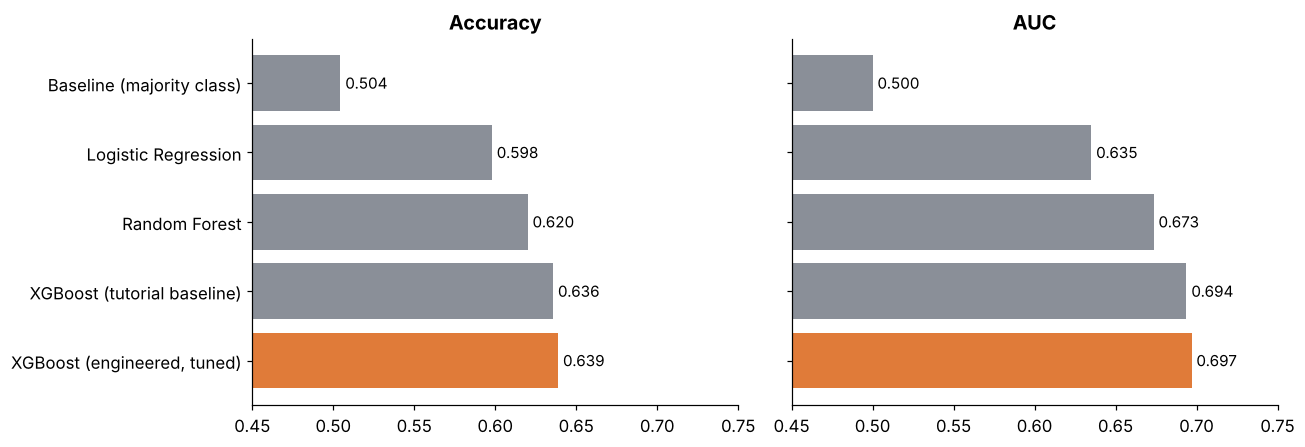

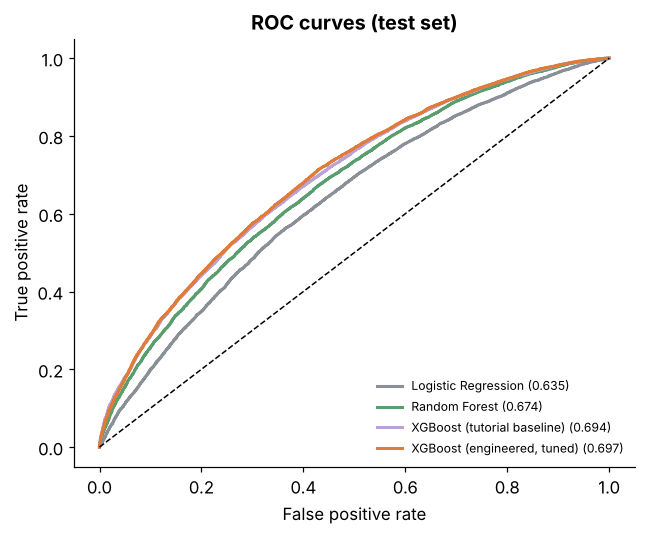

In [10]:
order = ["Baseline (majority class)", "Logistic Regression", "Random Forest", "XGBoost (tutorial baseline)", "XGBoost (engineered, tuned)"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, m, lo in zip(axs, ["Accuracy", "AUC"], [0.45, 0.45]):
    v = res.loc[order, m]
    ax.barh(order[::-1], v.values[::-1], color=[CHURN if n == order[-1] else GREY for n in order[::-1]])
    ax.set_xlim(lo, 0.75); ax.set_title(m)
    for i, x in enumerate(v.values[::-1]): ax.text(x+0.003, i, f"{x:.3f}", va="center", fontsize=10)
save("05_model_comparison")

plt.figure(figsize=(6, 5))
for n, col in zip(order[1:], [GREY, "#5A9E6F", "#B9A3D6", CHURN]):
    f, t_, _ = roc_curve(yte, probas[n]); plt.plot(f, t_, label=f"{n} ({results[n]['AUC']:.3f})", color=col, lw=2)
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.legend(frameon=False, fontsize=8, loc="lower right"); plt.title("ROC curves (test set)")
save("06_roc")

**Model choice:** XGBoost with engineered features is best on both accuracy and AUC. The step up from logistic regression (+4 points accuracy, +0.06 AUC) shows churn depends on **non-linear thresholds** (e.g. handset age ~300 days) that a straight-line model misses. Feature engineering added only a small extra gain (+0.3 points) over the tutorial XGBoost. Absolute scores are modest (~0.64 accuracy, ~0.70 AUC) because customer behaviour is noisy; for a campaign we only need good **ranking**, not perfect prediction.

### 6.1 Confusion matrix and what drives the model

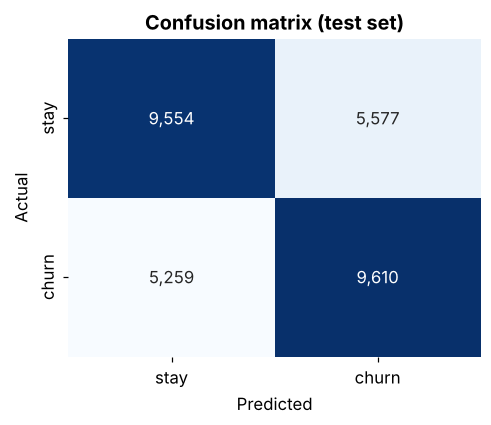

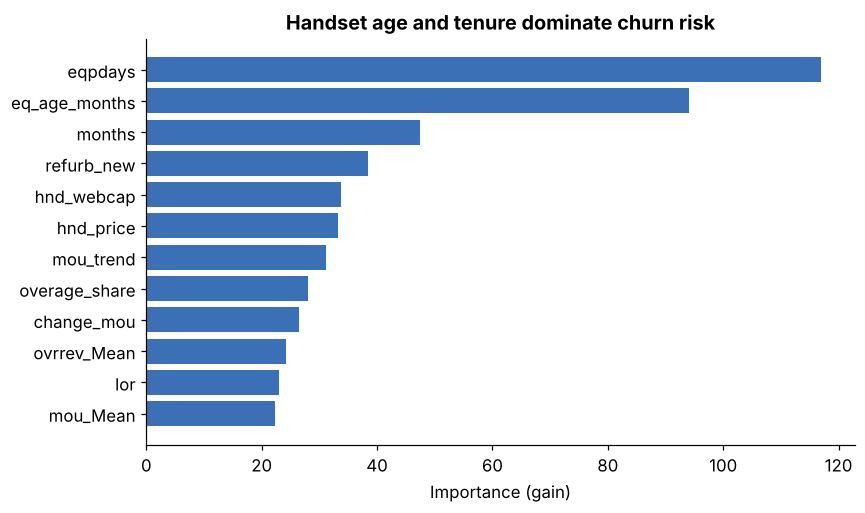

eqpdays          116.9
eq_age_months     94.0
months            47.5
refurb_new        38.4
hnd_webcap        33.7
hnd_price         33.2
mou_trend         31.2
overage_share     28.0
change_mou        26.5
ovrrev_Mean       24.2
lor               23.0
mou_Mean          22.4
dtype: float64


In [11]:
best = "XGBoost (engineered, tuned)"
pred = (probas[best] > .5).astype(int)
cm = confusion_matrix(yte, pred)
plt.figure(figsize=(4.6, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, xticklabels=["stay", "churn"], yticklabels=["stay", "churn"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test set)")
save("07_confusion")

imp = pd.Series(xgb.get_booster().get_score(importance_type="gain")).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(imp.index[::-1], imp.values[::-1], color=STAY); ax.set_xlabel("Importance (gain)")
ax.set_title("Handset age and tenure dominate churn risk")
save("08_importance")
print(imp.round(1))

In [12]:
# Robustness check from the tutorial: remove the handset-age features and retrain. Is the story one signal or many?
drop_eq = ["eqpdays", "eq_age_months", "eq_vs_tenure"]
x2 = XGBClassifier(n_estimators=600, learning_rate=0.04, max_depth=4, subsample=0.8, colsample_bytree=0.7,
                   enable_categorical=True, tree_method="hist", random_state=SEED, n_jobs=2)
x2.fit(Xtr.drop(columns=drop_eq), ytr)
p2 = x2.predict_proba(Xte.drop(columns=drop_eq))[:, 1]
print(f"AUC without handset-age features: {roc_auc_score(yte, p2):.4f}  (with: {results[best]['AUC']:.4f})")
print(f"Accuracy without: {accuracy_score(yte, p2>.5):.4f}  (with: {results[best]['Accuracy']:.4f})")

AUC without handset-age features: 0.6925  (with: 0.6969)
Accuracy without: 0.6384  (with: 0.6388)


Removing the handset-age features barely changes the score (AUC 0.697 -> 0.693). So the ranking does **not** hinge on one column: other fields that move with handset age (tenure, handset price/type, refurbished flag) carry much of the same information. This is useful for the client: the signal is robust, and the *action* (handset upgrade) is still the one lever Company A can pull, because tenure and handset price cannot be changed but handset age can.

## 7. From model to business proposal

### 7.1 Who to call? Gains and lift

                 Precision (share who really churn)  \
Top % contacted                                       
5                                             0.837   
10                                            0.785   
20                                            0.736   
30                                            0.693   
40                                            0.662   
50                                            0.634   

                 Churners captured (recall)  Lift vs random  
Top % contacted                                              
5                                     0.084           1.689  
10                                    0.158           1.583  
20                                    0.297           1.485  
30                                    0.420           1.399  
40                                    0.534           1.335  
50                                    0.640           1.280  

Rule 'handset >= 300 days': contacts 60% of customers, precisi

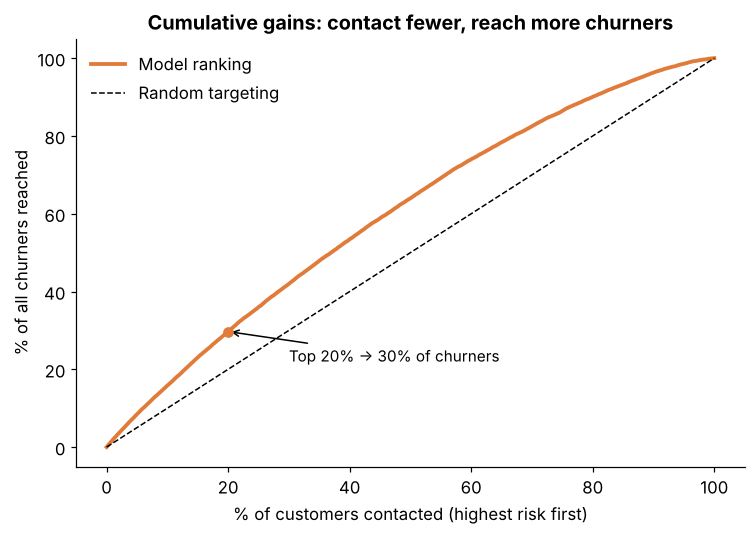

In [13]:
ev = pd.DataFrame({"y": yte.values, "p": probas[best], "rev": X.loc[yte.index, "rev_Mean"].values, "eqd": X.loc[yte.index, "eqpdays"].values})
ev = ev.sort_values("p", ascending=False).reset_index(drop=True)
N = len(ev); base_rate = ev.y.mean()
ev["cum_churners"] = ev.y.cumsum()
rows = []
for k in [5, 10, 20, 30, 40, 50]:
    n = int(N * k / 100); caught = ev.y.iloc[:n].sum()
    rows.append({"Top % contacted": k, "Precision (share who really churn)": ev.y.iloc[:n].mean(),
                 "Churners captured (recall)": caught / ev.y.sum(), "Lift vs random": ev.y.iloc[:n].mean() / base_rate})
gain = pd.DataFrame(rows).set_index("Top % contacted"); print(gain.round(3))

# Simple rule-based alternative: just target every customer with handset >= 300 days
rule = ev.eqd >= 300
print(f"\nRule 'handset >= 300 days': contacts {rule.mean():.0%} of customers, precision {ev.y[rule].mean():.1%}, recall {ev.y[rule].sum()/ev.y.sum():.1%}")
top = ev.iloc[:int(rule.mean() * N)]
print(f"Model, same contact volume ({rule.mean():.0%}): precision {top.y.mean():.1%}, recall {top.y.sum()/ev.y.sum():.1%}")

x = np.arange(1, N + 1) / N * 100
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, ev.cum_churners / ev.y.sum() * 100, color=CHURN, lw=2.5, label="Model ranking")
ax.plot([0, 100], [0, 100], "k--", lw=1, label="Random targeting")
ax.scatter([20], [gain.loc[20, "Churners captured (recall)"] * 100], color=CHURN, zorder=5)
ax.annotate(f"Top 20% -> {gain.loc[20, 'Churners captured (recall)']*100:.0f}% of churners", (20, gain.loc[20, "Churners captured (recall)"]*100), xytext=(30, 22), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("% of customers contacted (highest risk first)"); ax.set_ylabel("% of all churners reached")
ax.set_title("Cumulative gains: contact fewer, reach more churners"); ax.legend(frameon=False)
save("09_gains")

### 7.2 Business case: transparent assumptions
Company A did not share costs or margins, so these are **assumptions (edit them in the cell below)**:

| Assumption | Base value | Basis |
|---|---|---|
| Avg monthly revenue per customer (ARPU) | from data (`rev_Mean`) | dataset |
| Contribution margin on revenue | 35% | assumption |
| Months of extra revenue from a saved customer | 12 | assumption |
| Offer success rate (churner stays because of the offer) | 15% | assumption, tested 5-30% |
| Cost per customer contacted (SMS/call + expected upgrade discount) | $15 | assumption, tested $5-30 |

In [14]:
ARPU   = ev.rev.mean()                         # average monthly revenue per customer in the test set
MARGIN, MONTHS, SUCCESS, COST = 0.35, 12, 0.15, 15.0
VALUE_SAVED = ARPU * MARGIN * MONTHS            # profit from one saved customer
print(f"ARPU = ${ARPU:.2f}/month  ->  value of one saved customer = ${VALUE_SAVED:,.0f}")

def campaign(frac, success=SUCCESS, cost=COST, value=VALUE_SAVED, targeting="model"):
    n = int(N * frac)
    if targeting == "model": churners = ev.y.iloc[:n].sum()
    else:                    churners = base_rate * n          # random targeting hits the average churn rate
    saved = churners * success
    return saved * value - n * cost, saved, n

rows = []
for k in [5, 10, 20, 30, 50]:
    pm, sm, n = campaign(k / 100); pr, sr, _ = campaign(k / 100, targeting="random")
    scale = 100000 / N
    rows.append({"Contact top %": k, "Customers contacted (of 100k)": int(n*scale), "Churners saved (model)": sm*scale,
                 "Profit, model ($)": pm*scale, "Profit, random ($)": pr*scale, "Extra profit from ML ($)": (pm-pr)*scale})
biz = pd.DataFrame(rows).set_index("Contact top %"); print(biz.round(0).astype(int))

ARPU = $58.47/month  ->  value of one saved customer = $246
               Customers contacted (of 100k)  Churners saved (model)  \
Contact top %                                                          
5                                       5000                     628   
10                                     10000                    1177   
20                                     20000                    2208   
30                                     30000                    3120   
50                                     50000                    4756   

               Profit, model ($)  Profit, random ($)  Extra profit from ML ($)  
Contact top %                                                                   
5                          79209               16279                     62930  
10                        139019               32558                    106461  
20                        242187               65116                    177070  
30                        3161

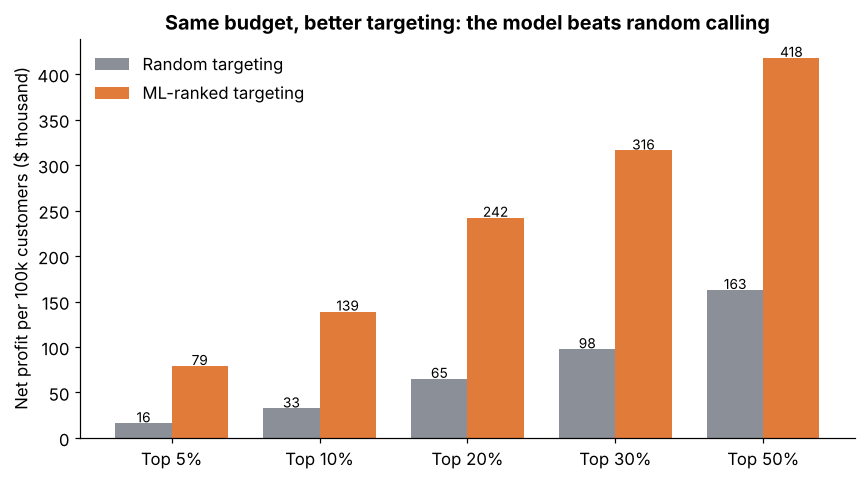

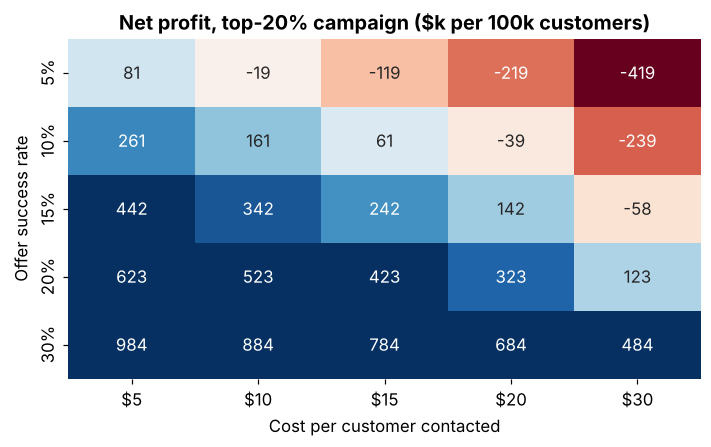

        $5    $10    $15    $20    $30
5%    81.0  -19.0 -119.0 -219.0 -419.0
10%  261.0  161.0   61.0  -39.0 -239.0
15%  442.0  342.0  242.0  142.0  -58.0
20%  623.0  523.0  423.0  323.0  123.0
30%  984.0  884.0  784.0  684.0  484.0


In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
w = 0.38; idx = np.arange(len(biz))
ax.bar(idx - w/2, biz["Profit, random ($)"]/1e3, w, color=GREY, label="Random targeting")
ax.bar(idx + w/2, biz["Profit, model ($)"]/1e3, w, color=CHURN, label="ML-ranked targeting")
ax.set_xticks(idx); ax.set_xticklabels([f"Top {k}%" for k in biz.index]); ax.set_ylabel("Net profit per 100k customers ($ thousand)")
ax.set_title("Same budget, better targeting: the model beats random calling"); ax.legend(frameon=False)
for i, (a, b) in enumerate(zip(biz["Profit, random ($)"]/1e3, biz["Profit, model ($)"]/1e3)):
    ax.text(i - w/2, a + 1, f"{a:.0f}", ha="center", fontsize=9); ax.text(i + w/2, b + 1, f"{b:.0f}", ha="center", fontsize=9)
save("10_profit")

# sensitivity: NET profit of the top-20% campaign, varying success rate and cost per contacted customer
succ = [0.05, 0.10, 0.15, 0.20, 0.30]; costs = [5, 10, 15, 20, 30]
sens = pd.DataFrame([[campaign(.2, s, c)[0] * 100000 / N / 1e3 for c in costs] for s in succ],
                    index=[f"{int(s*100)}%" for s in succ], columns=[f"${c}" for c in costs])
plt.figure(figsize=(6.6, 4.2))
sns.heatmap(sens, annot=True, fmt=".0f", cmap="RdBu", center=0, cbar=False, vmin=-400, vmax=400)
plt.xlabel("Cost per customer contacted"); plt.ylabel("Offer success rate")
plt.title("Net profit, top-20% campaign ($k per 100k customers)")
save("11_sensitivity")
print(sens.round(0))

### 7.3 Honest limits and risks
- **Balanced sample:** Company A's data has ~50% churn, far above the 0.75-5% monthly range in the industry literature. In a normal customer base the *same model* would find fewer true churners per call, so Company A should confirm that this extract is representative (or re-sampled) before the PoC is scaled.
- **Absolute profit depends on assumptions** (success rate, offer cost, margin). The **lift over random targeting** (about 1.5x at the top 20%) is measured from the data and does not depend on them.
- **Correlation, not causation:** the model shows *who* is at risk; a small A/B test (offer vs no offer) is needed to measure the real success rate.
- **Voluntary vs involuntary churn** is not labelled; non-payment churn cannot be fixed by an upgrade offer.

In [16]:
# Prior-shift stress test: what if Company A's real monthly churn is only 5%?  Re-weight the same test-set scores.
pi = 0.05
pos, neg = ev.y.sum(), (1 - ev.y).sum()
for k in [5, 10, 20]:
    n = int(N * k / 100); tp = ev.y.iloc[:n].sum(); fp = n - tp
    tpr, fpr = tp / pos, fp / neg
    prec = tpr * pi / (tpr * pi + fpr * (1 - pi))
    print(f"Top {k:>2}%: precision at 5% base churn = {prec:.1%}  (random would be 5.0%)  lift = {prec/pi:.2f}x")

Top  5%: precision at 5% base churn = 21.6%  (random would be 5.0%)  lift = 4.32x
Top 10%: precision at 5% base churn = 16.3%  (random would be 5.0%)  lift = 3.27x
Top 20%: precision at 5% base churn = 13.0%  (random would be 5.0%)  lift = 2.60x


At a 5% base churn rate the model's lift over random is even larger (about 2.6x at the top 20%), but only ~13% of those contacted would really be leavers. With a $15 offer and 15% success the campaign would then lose money, so a cheap channel (SMS/app push, about $3-5) or a smaller top slice is needed. Hence the recommendation to run a **small A/B pilot first** and to confirm the real churn rate.

## 8. Summary of key numbers (used on the slides)

In [17]:
print(f"Best model: XGBoost | accuracy {results[best]['Accuracy']:.3f} | AUC {results[best]['AUC']:.3f}")
print(f"Logistic Regression: accuracy {results['Logistic Regression']['Accuracy']:.3f} | AUC {results['Logistic Regression']['AUC']:.3f}")
print(gain.loc[[10, 20, 30]].round(3))
print(biz.loc[[10, 20, 30]].round(0).astype(int))

Best model: XGBoost | accuracy 0.639 | AUC 0.697
Logistic Regression: accuracy 0.598 | AUC 0.635
                 Precision (share who really churn)  \
Top % contacted                                       
10                                            0.785   
20                                            0.736   
30                                            0.693   

                 Churners captured (recall)  Lift vs random  
Top % contacted                                              
10                                    0.158           1.583  
20                                    0.297           1.485  
30                                    0.420           1.399  
               Customers contacted (of 100k)  Churners saved (model)  \
Contact top %                                                          
10                                     10000                    1177   
20                                     20000                    2208   
30                           

## 9. References
See the reference list submitted on Omnicampus (also on the last slide). Includes STL Partners (telco economics), arXiv:1607.07792 (Customer Churn in Mobile Markets), PTA/Profit (Pakistan subscribers), PhoneWorld (market share), the course tutorial notebook, and the URL of the AI chat used.